Los sistemas de bicicletas compartidas como Capital Bikeshare en Washington D.C. necesitan redistribuir bicicletas entre estaciones a lo largo del día: si hay demasiadas en un punto y ninguna en otro, el sistema falla. Anticipar cuántas bicicletas se van a necesitar en cada franja horaria permite optimizar la logística y reducir los costos operativos.

El dataset contiene registros hora a hora durante dos años, con información sobre condiciones climáticas (temperatura, humedad, viento, si llueve o nieva), el día de la semana, si es feriado, si es día hábil, y la estación del año. El objetivo es predecir la cantidad total de viajes realizados en cada hora.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
from ucimlrepo import fetch_ucirepo
ds = fetch_ucirepo(id=275)

In [ ]:
ds.keys() #ds es un diccionario con claves data, metadata y variables. Exploraremos cada una

dict_keys(['data', 'metadata', 'variables'])

In [ ]:
ds['variables']

,name,role,type,demographic,description,units,missing_values
0,instant,ID,Integer,None,record index,None,no
1,dteday,Feature,Date,None,date,None,no
2,season,Feature,Categorical,None,"1:winter, 2:spring, 3:summer, 4:fall",None,no
3,yr,Feature,Categorical,None,"year (0: 2011, 1: 2012)",None,no
4,mnth,Feature,Categorical,None,month (1 to 12),None,no
5,hr,Feature,Categorical,None,hour (0 to 23),None,no
6,holiday,Feature,Binary,None,weather day is holiday or not (extracted from ...,None,no
7,weekday,Feature,Categorical,None,day of the week,None,no
8,workingday,Feature,Binary,None,"if day is neither weekend nor holiday is 1, ot...",None,no
9,weathersit,Feature,Categorical,None,"- 1: Clear, Few clouds, Partly cloudy, Partly ...",None,no


Vemos que ds['variables'] es un dataframe que directamente describe los tipos y roles de los 16 features y el target, el cual se establece que es cnt (count), un valor entero (la cantidad de usuarios de bicicletas para la hora correspondiente). Además, se tiene el instante de registro como id de la instancia, que es una fecha especificada a nivel de horas. La temperatura y la sensación térmica son las únicas variables que tienen unidad (se miden en °C). Observamos que el target es un número entero que en principio no tiene cota superior, por lo que estamos ante un problema de regresión. Se informa que no hay valores faltantes en ningún feature ni en el target. Como algunas descripciones no se leen completas en esta primera visión, las desplegamos directamente.

In [16]:
ds['variables'].loc[6,'description'] #'weather day is holiday or not (extracted from http://dchr.dc.gov/page/holiday-schedule)'
ds['variables'].loc[8,'description'] #'if day is neither weekend nor holiday is 1, otherwise is 0'
ds['variables'].loc[9,'description'] #'- 1: Clear, Few clouds, Partly cloudy, Partly cloudy'
ds['variables'].loc[10,'description'] #'Normalized temperature in Celsius. The values are derived via (t-t_min)/(t_max-t_min), t_min=-8, t_max=+39 (only in hourly scale)'
ds['variables'].loc[11,'description'] #'Normalized feeling temperature in Celsius. The values are derived via (t-t_min)/(t_max-t_min), t_min=-16, t_max=+50 (only in hourly scale)'
ds['variables'].loc[12,'description'] #'Normalized humidity. The values are divided to 100 (max)'
ds['variables'].loc[13,'description'] #'Normalized wind speed. The values are divided to 67 (max)'
ds['variables'].loc[16,'description'] #'count of total rental bikes including both casual and registered'

'count of total rental bikes including both casual and registered'

In [ ]:
ds['metadata']
#weathersit : \r\n\t\t- 1: Clear, Few clouds, Partly cloudy, Partly cloudy\r\n\t\t-
# 2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist\r\n\t\t-
# 3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds\r\n\t\t-
# 4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog\r\n\t-

{'uci_id': 275,
 'name': 'Bike Sharing',
 'repository_url': 'https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset',
 'data_url': 'https://archive.ics.uci.edu/static/public/275/data.csv',
 'abstract': 'This dataset contains the hourly and daily count of rental bikes between years 2011 and 2012 in Capital bikeshare system with the corresponding weather and seasonal information.',
 'area': 'Social Science',
 'tasks': ['Regression'],
 'characteristics': ['Multivariate'],
 'num_instances': 17389,
 'num_features': 13,
 'feature_types': ['Integer', 'Real'],
 'demographics': [],
 'target_col': ['cnt'],
 'index_col': ['instant'],
 'has_missing_values': 'no',
 'missing_values_symbol': None,
 'year_of_dataset_creation': 2013,
 'last_updated': 'Sun Mar 10 2024',
 'dataset_doi': '10.24432/C5W894',
 'creators': ['Hadi Fanaee-T'],
 'intro_paper': {'ID': 422,
  'type': 'NATIVE',
  'title': 'Event labeling combining ensemble detectors and background knowledge',
  'authors': 'Hadi Fanaee-T, João

Vemos que hay 17.389 instancias y ninguna partición recomendada para los datos, de forma que la definiremos nosotros.

In [ ]:
ds['data']

{'ids':        instant
 0            1
 1            2
 2            3
 3            4
 4            5
 ...        ...
 17374    17375
 17375    17376
 17376    17377
 17377    17378
 17378    17379
 
 [17379 rows x 1 columns],
 'features':            dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
 0      2011-01-01       1   0     1   0        0        6           0   
 1      2011-01-01       1   0     1   1        0        6           0   
 2      2011-01-01       1   0     1   2        0        6           0   
 3      2011-01-01       1   0     1   3        0        6           0   
 4      2011-01-01       1   0     1   4        0        6           0   
 ...           ...     ...  ..   ...  ..      ...      ...         ...   
 17374  2012-12-31       1   1    12  19        0        1           1   
 17375  2012-12-31       1   1    12  20        0        1           1   
 17376  2012-12-31       1   1    12  21        0        1           1   
 17377  2012-12-31  

In [ ]:
ds['data']['ids']

,instant
0,1
1,2
2,3
3,4
4,5
...,...
17374,17375
17375,17376
17376,17377
17377,17378


Como el atributo instant sirve como id, y por lo tanto no tiene repetidos, además de que va de 1 a 17.379 en 17.379 filas, deducimos que este feature es intercambiable con el índice mismo de la tabla (hay una biyección entre instant e index).

In [20]:
ds['data']['features']

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000
1,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000
2,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000
3,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000
4,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642
17375,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642
17376,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642
17377,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343


In [21]:
ds['data']['headers']

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

A continuación nos hacemos algunas preguntas sobre los datos para comprenderlos mejor:
1) ¿Se dispone de datos para todos los días y horarios?
2) ¿Qué columnas de ds['variables'] no están en ds['data']['features']?
3) ¿Es cnt realmente suma de casual y registered?
4) ¿Hay muchas diferencias entre las mismas fechas de los dos años?
5) ¿Hay estacionalidad marcada?

Para la pregunta 2), vemos que los atributos que no se transfirieron son instant (que ya vimos que equivale al índice), cnt que es el target, y casual y registered que son los valores cuya suma da cnt de acuerdo a la información que la base de datos nos da. Es decir, ya tenemos una tabla con los features y sin el target.

Sobre la pregunta 1, como 2011 y 2012 son años no bisiestos, la cantidad de combinaciones diferentes de año, día y hora son 365x2x24 = 17520, y tenemos 17379 registros. En otras palabras, hay 141 combinaciones de año, hora y día que no aparecen, un promedio de 70,5 por año (sobre 8760, por lo que podemos asumir que tenemos un registro muy completo).

In [7]:
df_completo = ds['data']['original']
df_completo[df_completo['casual']+df_completo['registered'] == df_completo['cnt']] #esto vale en todos los casos,
#por lo que respondemos afirmativamente la pregunta 3.

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61


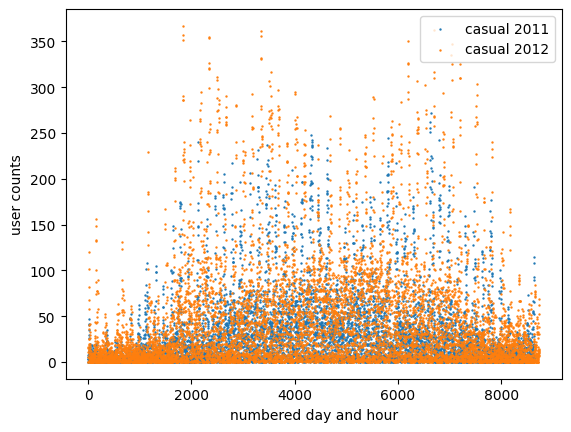

In [10]:
#Para responder la pregunta 4, graficamos casual y registered en función del día y hora (que tomaremos como los índices de las filas).
fig, ax = plt.subplots()
df_2011 = df_completo[df_completo['yr']==0] #8645 registros
df_2012 = df_completo[df_completo['yr']==1].reset_index() #8734 registros
dia_hora_2011 = np.array([i for i in range(8645)])
registered_2011 = np.array(df_2011['registered'])
casual_2011 = np.array(df_2011['casual'])
dia_hora_2012 = np.array([i for i in range(8734)])
registered_2012 = np.array(df_2012['registered'])
casual_2012 = np.array(df_2012['casual'])
#ax.scatter(dia_hora_2011,registered_2011,label='registered 2011',s=0.5)
ax.scatter(dia_hora_2011,casual_2011,label='casual 2011',s=0.5)
#ax.scatter(dia_hora_2012,registered_2012,label='registered 2012',s=0.5)
ax.scatter(dia_hora_2012,casual_2012,label='casual 2012',s=0.5)
ax.set_xlabel('numbered day and hour')
ax.set_ylabel('user counts')
ax.legend()
plt.show()


Observamos entre los registered un mayor uso consistente en 2012, probablemente porque después de un año la gente conocía más el sistema de bicicletas compartidas. Por otro lado, vemos estacionalidad: tienden a usar más el sistema en la segunda mitad del año, sobre todo entre los registros 2000 y 7500 (entre abril y mediados de octubre aproximadamente, ya que vimos que el registro de días y horas de todo el año está casi completo). Vemos así una estacionalidad marcada, ya que el uso de bicicletas aumenta en primavera y verano.
Por otro lado, las cantidades de usuarios suben y bajan muy rápidamente, de lo que deducimos una fuerte influencia de la hora del día (tiene sentido, en general se usará muchas más bicicletas de día que de noche). Se ve las mismas tendencias entre los usuarios casuales, aunque con una cantidad notablemente menor de usuarios de este tipo respecto de los registered. 

Sospechamos que habrá menos ciclistas casual en días laborables, mientras que en el caso de los registered no está tan claro porque pueden usar más la bicicleta para ir al trabajo, la escuela o la universidad o menos porque hay menos tiempo libre. También creemos que el viento, la humedad y la temperatura influyen en la cantidad de usos de bicicletas (cada uno reduciría el uso en los extremos y lo maximizaría en algún punto intermedio).

In [4]:
df_completo.groupby(by='weathersit').count()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,hum,windspeed,casual,registered,cnt
weathersit,,,,,,,,,,,,,,,,
1,11413,11413,11413,11413,11413,11413,11413,11413,11413,11413,11413,11413,11413,11413,11413,11413
2,4544,4544,4544,4544,4544,4544,4544,4544,4544,4544,4544,4544,4544,4544,4544,4544
3,1419,1419,1419,1419,1419,1419,1419,1419,1419,1419,1419,1419,1419,1419,1419,1419
4,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3


Notamos que el caso de weathersit 4 es estadísticamente insignificante, lo que resulta normal dado que es una condición climática extrema. Como son sólo 3 casos, no creemos necesario que el modelo aprenda a predecir el uso de bicicletas en esta situación. Sí nos parece importante predecir bien el uso para los weathersit 2 y 3, que aparecen mucho menos que el 1 pero son relativamente comunes.